In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna     = gleap_target.topology.select("resid  7 to  16")
atom_indices_rna     = gleap_target.topology.select("resid 11 to  14")


xtcs = []
interactions = np.zeros((5, 18000))
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    xtcs.append(xtc)
    print(trial, xtc.n_frames)

    coms_protein = md.compute_center_of_mass(xtc.atom_slice(atom_indices_protein))
    coms_rna     = md.compute_center_of_mass(xtc.atom_slice(atom_indices_rna))
    com_distances = np.linalg.norm(coms_rna-coms_protein, axis=1)

    interactions[trial] = com_distances

0 18000
1 18000
2 18000
3 18000
4 18000


0 18000 1.1622048582276463 0.06136144420604547
1 18000 1.26159264977523 0.04998161934640757
2 18000 1.1772300264573299 0.08493051628496605
3 18000 1.3489070034458008 0.07006098207302996
4 18000 1.3107361154123782 0.06406378787536847


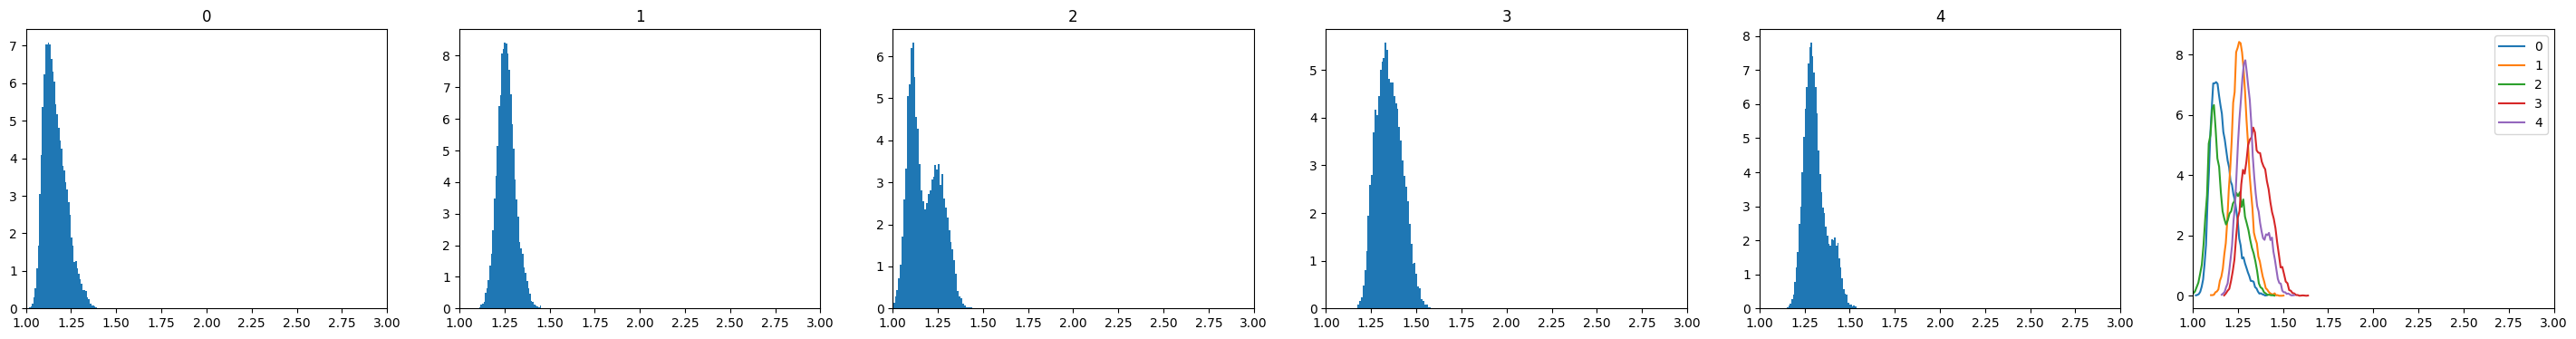

In [2]:
fig, ax = plt.subplots(1, 6)
fig.set_size_inches(36, 4)

for trial in range(5):
    print(trial, xtc.n_frames, interactions[trial].mean(), interactions[trial].std())
    hist = ax[trial].hist(interactions[trial], bins=50, density=True)
    ax[trial].set_title(trial)
    ax[trial].set_xlim(1, 3)

    ax[5].plot(hist[1][1:], hist[0], label=trial)
    ax[5].set_xlim(1, 3)
    ax[5].legend()

(24995,) 1.1308488400977323 0.045044499539931324
(65005,) 1.2987694023765575 0.07055489982968371


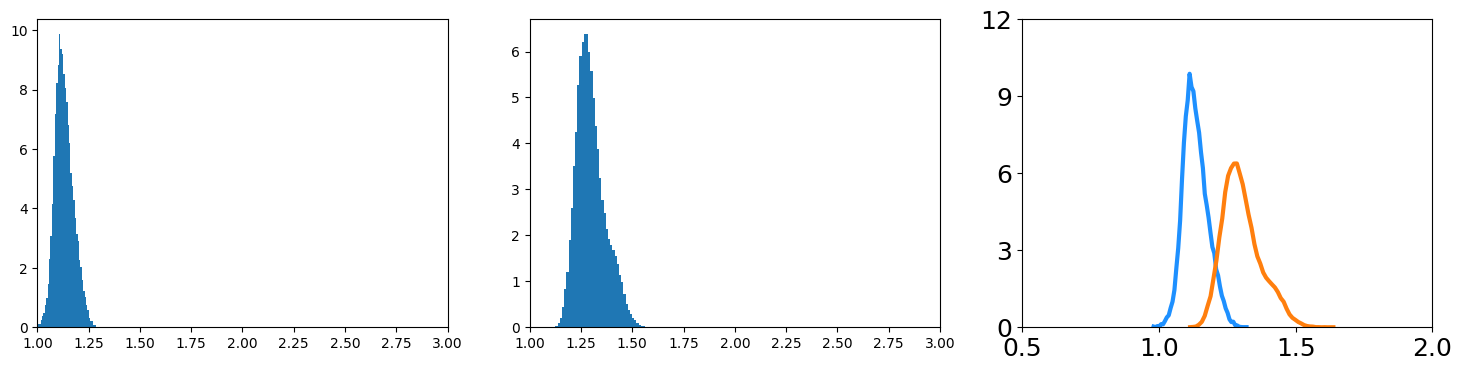

In [3]:
fig, ax = plt.subplots(1, 3)
fig.set_size_inches(18, 4)


metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))
interactions_concat = np.concatenate(interactions)

colors = ["#1E90FF", "tab:orange"]
for i_state in range(2):
    interactions_concat_state = interactions_concat[metastabled_trajs_concat==i_state]
    print(interactions_concat_state.shape, interactions_concat_state.mean(), interactions_concat_state.std())
    hist = ax[i_state].hist(interactions_concat_state, bins=50, density=True)
    ax[i_state].set_xlim(1, 3)
    ax[2].plot(hist[1][1:], hist[0], label=trial, color=colors[i_state], linewidth=3)
    ax[2].set_xlim(0.5, 2)
    ax[2].set_xticks([0.5, 1, 1.5, 2])
    ax[2].tick_params(axis='x', labelsize=18)
    ax[2].set_ylim(0, 12)
    ax[2].set_yticks([0, 3, 6, 9, 12])
    ax[2].tick_params(axis='y', labelsize=18)